# Magic window — lat / lon / bathymetry overview

This notebook loads `magic_window_lat_lon_bathymetry_wh(1).pt` and summarizes the fixed ocean patch it contains.

The file stores a **rectangular window** cut from the Guiana margin dataset (`margem_equatorial.zarr`): per-pixel latitude, longitude, and bathymetry on a regular grid.

In [1]:
from pathlib import Path
import os
import sys

NOTEBOOK_DIR = Path.cwd().resolve()
MW_DIR = NOTEBOOK_DIR if NOTEBOOK_DIR.name == "Magic_window" else NOTEBOOK_DIR / "Magic_window"
ROOT = MW_DIR.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import pandas as pd
import torch
import zarr
from matplotlib.patches import Rectangle

PT_PATH = MW_DIR / "magic_window_lat_lon_bathymetry_wh(1).pt"
if not PT_PATH.exists():
    raise FileNotFoundError(f"Expected file at {PT_PATH}")

data = torch.load(PT_PATH, map_location="cpu", weights_only=False)
print(f"Loaded: {PT_PATH.name}")
print(f"Top-level keys: {list(data.keys())}")


Loaded: magic_window_lat_lon_bathymetry_wh(1).pt
Top-level keys: ['tensor', 'channels', 'shape_order', 'magic_window', 'row_slice', 'col_slice', 'source_zarr']


## File structure

| Key | Role |
|-----|------|
| `tensor` | Float32 array, shape `(3, width, height)` with channels `lat`, `lon`, `bathymetry` |
| `channels` | Channel names |
| `shape_order` | Layout convention (`channel,width,height`) |
| `magic_window` | Normalized `(lat_frac, lon_frac)` slice on the parent zarr grid |
| `row_slice`, `col_slice` | Integer index ranges used to extract this patch |
| `source_zarr` | Path to the source dataset |

In [2]:
tensor = data["tensor"].numpy()
channels = data["channels"]
shape_order = data["shape_order"]
magic_window = data["magic_window"]
row_slice = data["row_slice"]
col_slice = data["col_slice"]
source_zarr = data["source_zarr"]

ch_idx = {name: i for i, name in enumerate(channels)}
lat = tensor[ch_idx["lat"]]
lon = tensor[ch_idx["lon"]]
bathy = tensor[ch_idx["bathymetry"]]

width, height = lat.shape  # lon × lat in stored patch
lon_1d = lon[:, 0]
lat_1d = lat[0, :]
n_rows = row_slice[1] - row_slice[0]
n_cols = col_slice[1] - col_slice[0]

# Training/export window on parent grid (matches 01_export_magic_window.ipynb)
EXPORT_ROW_SLICE = row_slice
EXPORT_COL_SLICE = (85, 213)  # 128 cols → 128×128 with row_slice
patch_col_start = EXPORT_COL_SLICE[0] - col_slice[0]
patch_col_end = EXPORT_COL_SLICE[1] - col_slice[0]
bathy_full_patch = bathy
bathy_selected = bathy[patch_col_start:patch_col_end, :]
lat_selected = lat[patch_col_start:patch_col_end, :]
lon_selected = lon[patch_col_start:patch_col_end, :]
lon_1d_selected = lon_selected[:, 0]
lat_1d_selected = lat_selected[0, :]

meta_rows = [
    ("channels", ", ".join(channels)),
    ("shape_order", shape_order),
    ("tensor shape (C, W, H)", str(tuple(tensor.shape))),
    ("grid size (width × height)", f"{width} × {height}"),
    ("magic_window (lat frac, lon frac)", str(magic_window)),
    ("row_slice", str(row_slice)),
    ("col_slice (.pt extract)", str(col_slice)),
    ("export col_slice (128×128)", str(EXPORT_COL_SLICE)),
    ("extracted rows / cols", f"{n_rows} / {n_cols}"),
    ("source_zarr", source_zarr),
]
display(pd.DataFrame(meta_rows, columns=["field", "value"]))

parent_h = row_slice[0] / magic_window[0][0]
parent_w = col_slice[0] / magic_window[1][0]
print(f"\nInferred parent zarr size ≈ {parent_h:.0f} rows × {parent_w:.0f} cols")
print(
    f"Selected export window inside patch: cols [{patch_col_start}:{patch_col_end}] "
    f"→ {bathy_selected.shape[0]}×{bathy_selected.shape[1]}"
)


,field,value
0,channels,"lat, lon, bathymetry"
1,shape_order,"channel,width,height"
2,"tensor shape (C, W, H)","(3, 138, 128)"
3,grid size (width × height),138 × 128
4,"magic_window (lat frac, lon frac)","((0.524362, 0.821346), (0.146535, 0.4))"
5,row_slice,"(226, 354)"
6,col_slice (.pt extract),"(80, 218)"
7,export col_slice (128×128),"(85, 213)"
8,extracted rows / cols,128 / 138
9,source_zarr,../data/margem_equatorial.zarr



Inferred parent zarr size ≈ 431 rows × 546 cols
Selected export window inside patch: cols [5:133] → 128×128


## Geographic extent

The full tensor is the fixed window. Corner coordinates come directly from the `lat` and `lon` channels.

In [3]:
lat_min, lat_max = float(np.nanmin(lat)), float(np.nanmax(lat))
lon_min, lon_max = float(np.nanmin(lon)), float(np.nanmax(lon))
lat_center = 0.5 * (lat_min + lat_max)
lon_center = 0.5 * (lon_min + lon_max)

corners = {
    "SW (col=0, row=0)": (lat[0, 0], lon[0, 0]),
    "SE (col=W-1, row=0)": (lat[-1, 0], lon[-1, 0]),
    "NW (col=0, row=H-1)": (lat[0, -1], lon[0, -1]),
    "NE (col=W-1, row=H-1)": (lat[-1, -1], lon[-1, -1]),
}

extent_rows = [
    ("latitude range", f"{lat_min:.4f}°N – {lat_max:.4f}°N"),
    ("longitude range", f"{lon_min:.4f}° – {lon_max:.4f}°"),
    ("center", f"{lat_center:.4f}°N, {lon_center:.4f}°"),
]
for name, (la, lo) in corners.items():
    extent_rows.append((name, f"lat={la:.4f}°, lon={lo:.4f}°"))

display(pd.DataFrame(extent_rows, columns=["location", "coordinates"]))

dlat_km = abs(lat[0, -1] - lat[0, 0]) / max(height - 1, 1) * 111.0
dlon_km = abs(lon[-1, 0] - lon[0, 0]) / max(width - 1, 1) * 111.0 * np.cos(np.radians(lat_center))
print(f"Approx. grid spacing: {dlat_km:.2f} km (lat) × {dlon_km:.2f} km (lon)")

,location,coordinates
0,latitude range,5.9493°N – 10.9723°N
1,longitude range,-59.8200° – -54.3400°
2,center,"8.4608°N, -57.0800°"
3,"SW (col=0, row=0)","lat=5.9493°, lon=-59.8200°"
4,"SE (col=W-1, row=0)","lat=5.9493°, lon=-54.3400°"
5,"NW (col=0, row=H-1)","lat=10.9723°, lon=-59.8200°"
6,"NE (col=W-1, row=H-1)","lat=10.9723°, lon=-54.3400°"


Approx. grid spacing: 4.39 km (lat) × 4.39 km (lon)


## Channel maps

Maps use 1-D lon/lat axes with `pcolormesh`. The stored `.pt` patch is **138 × 128** (lon × lat). Bathymetry uses **black for land/invalid** (NaN or exactly 0). The section below also compares the **full patch** vs the **128×128 export window** and the **full zarr domain** with the window outlined.


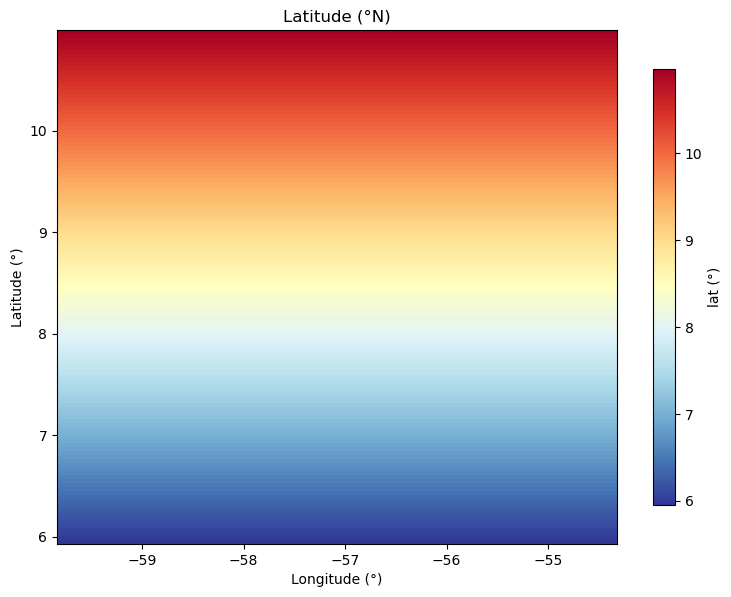

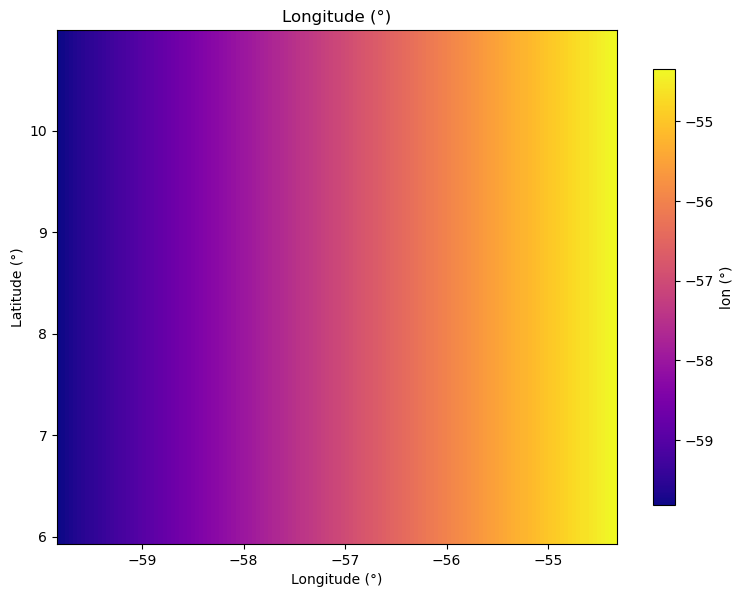

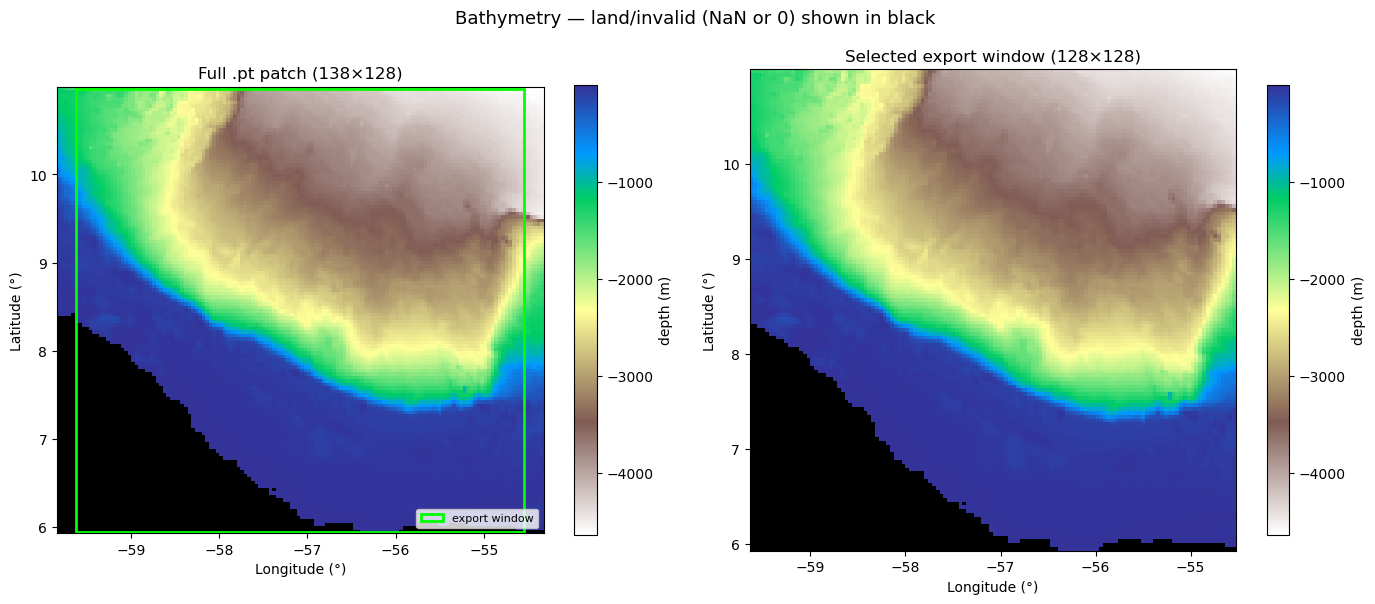

In [4]:
def bathymetry_cmap(base="terrain_r"):
    cmap = plt.get_cmap(base).copy()
    cmap.set_bad(color="black")
    cmap.set_under(color="black")
    return cmap


def mask_bathymetry_land(field: np.ndarray) -> np.ma.MaskedArray:
    """Mask land/invalid cells; plot them as black via set_bad."""
    land = ~np.isfinite(field) | (field == 0)
    return np.ma.masked_where(land, field)


def plot_bathymetry(
    field,
    lon_axis,
    lat_axis,
    title,
    *,
    ax=None,
    vmin=None,
    vmax=None,
    cbar_label="depth (m)",
    outline_rect=None,
):
    """Plot bathymetry with land (NaN / 0) in black.

    field: (n_lon, n_lat); pcolormesh uses field.T on (lat, lon) grid.
    outline_rect: optional (lon_min, lat_min, lon_width, lat_height) in geo coords.
    """
    masked = mask_bathymetry_land(field)
    if vmin is None:
        vmin = float(np.nanmin(field)) if np.any(np.isfinite(field)) else None
    if vmax is None:
        vmax = float(np.nanmax(field)) if np.any(np.isfinite(field)) else None

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))
    else:
        fig = ax.figure

    cmap = bathymetry_cmap()
    mesh = ax.pcolormesh(
        lon_axis,
        lat_axis,
        masked.T,
        shading="auto",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
    )
    if outline_rect is not None:
        lon0, lat0, lon_w, lat_h = outline_rect
        ax.add_patch(
            Rectangle(
                (lon0, lat0),
                lon_w,
                lat_h,
                fill=False,
                edgecolor="lime",
                linewidth=2,
                label="export window",
            )
        )
        ax.legend(loc="lower right", fontsize=8)
    ax.set_xlabel("Longitude (°)")
    ax.set_ylabel("Latitude (°)")
    ax.set_title(title)
    ax.set_aspect("equal")
    cbar = fig.colorbar(mesh, ax=ax, shrink=0.85)
    cbar.set_label(cbar_label)
    return fig, ax


def plot_geo_field(field, title, cmap="viridis", cbar_label=None, vmin=None, vmax=None):
    fig, ax = plt.subplots(figsize=(8, 6))
    mesh = ax.pcolormesh(lon_1d, lat_1d, field.T, shading="auto", cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xlabel("Longitude (°)")
    ax.set_ylabel("Latitude (°)")
    ax.set_title(title)
    ax.set_aspect("equal")
    cbar = fig.colorbar(mesh, ax=ax, shrink=0.85)
    if cbar_label:
        cbar.set_label(cbar_label)
    plt.tight_layout()
    return fig, ax


plot_geo_field(lat, "Latitude (°N)", cmap="RdYlBu_r", cbar_label="lat (°)")
plt.show()

plot_geo_field(lon, "Longitude (°)", cmap="plasma", cbar_label="lon (°)")
plt.show()

# Shared color scale for patch vs selected window
_bathy_valid = bathy[np.isfinite(bathy) & (bathy != 0)]
_bathy_vmin = float(_bathy_valid.min()) if _bathy_valid.size else None
_bathy_vmax = float(_bathy_valid.max()) if _bathy_valid.size else None

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_bathymetry(
    bathy_full_patch,
    lon_1d,
    lat_1d,
    f"Full .pt patch ({width}×{height})",
    ax=axes[0],
    vmin=_bathy_vmin,
    vmax=_bathy_vmax,
    outline_rect=(
        float(lon_selected.min()),
        float(lat_selected.min()),
        float(lon_selected.max() - lon_selected.min()),
        float(lat_selected.max() - lat_selected.min()),
    ),
)
plot_bathymetry(
    bathy_selected,
    lon_1d_selected,
    lat_1d_selected,
    f"Selected export window ({bathy_selected.shape[0]}×{bathy_selected.shape[1]})",
    ax=axes[1],
    vmin=_bathy_vmin,
    vmax=_bathy_vmax,
)
fig.suptitle("Bathymetry — land/invalid (NaN or 0) shown in black", fontsize=13)
plt.tight_layout()
plt.show()


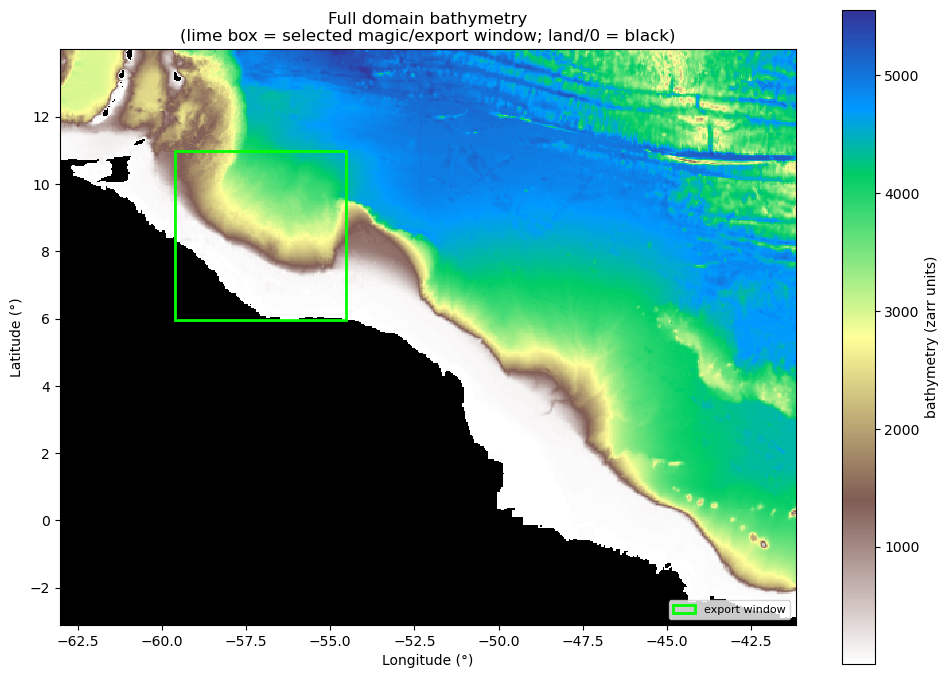

Parent grid rows/cols in .pt slices: (226, 354) × (85, 213) (matches export notebook)


In [5]:
ZARR_PATH = os.getenv(
    "GUIANA_ZARR_PATH",
    "s3://oceangen-data/margem_equatorial_tensor.zarr",
)

try:
    zgroup = zarr.open_group(ZARR_PATH, mode="r")
    ch_names = [
        c.decode() if isinstance(c, bytes) else str(c) for c in zgroup["channel"][:]
    ]
    bathy_idx = ch_names.index("bathymetry")
    full_bathy = np.asarray(zgroup["ocean_tensor"][0, 0, bathy_idx])  # (431, 547)
    full_lat_1d = np.asarray(zgroup["lat"][:])
    full_lon_1d = np.asarray(zgroup["lon"][:])

    # Window outline in geo coordinates (from .pt lat/lon at export corners)
    win_lon_min = float(lon_selected.min())
    win_lon_max = float(lon_selected.max())
    win_lat_min = float(lat_selected.min())
    win_lat_max = float(lat_selected.max())

    fb_valid = full_bathy[np.isfinite(full_bathy) & (full_bathy != 0)]
    fb_vmin = float(fb_valid.min()) if fb_valid.size else None
    fb_vmax = float(fb_valid.max()) if fb_valid.size else None

    fig, ax = plt.subplots(figsize=(10, 8))
    plot_bathymetry(
        full_bathy.T,  # store as (n_lon, n_lat) for helper
        full_lon_1d,
        full_lat_1d,
        f"Full zarr domain ({full_bathy.shape[0]}×{full_bathy.shape[1]}) — {Path(ZARR_PATH).name}",
        ax=ax,
        vmin=fb_vmin,
        vmax=fb_vmax,
        cbar_label="bathymetry (zarr units)",
        outline_rect=(win_lon_min, win_lat_min, win_lon_max - win_lon_min, win_lat_max - win_lat_min),
    )
    ax.set_title(
        "Full domain bathymetry\n(lime box = selected magic/export window; land/0 = black)",
        fontsize=12,
    )
    plt.tight_layout()
    plt.show()

    print(
        f"Parent grid rows/cols in .pt slices: {EXPORT_ROW_SLICE} × {EXPORT_COL_SLICE} "
        f"(matches export notebook)"
    )
except Exception as exc:
    print(f"Could not load full-domain bathymetry from {ZARR_PATH}: {exc}")


## Combined overview

Single figure with lat, lon, bathymetry, and the window bounding box.

,stat,value
0,valid ocean cells,15076 / 17664 (85.3%)
1,land/invalid (NaN or 0),2588
2,min depth (m),-4639.3
3,max depth (m),-3.0
4,mean depth (m),-1897.7


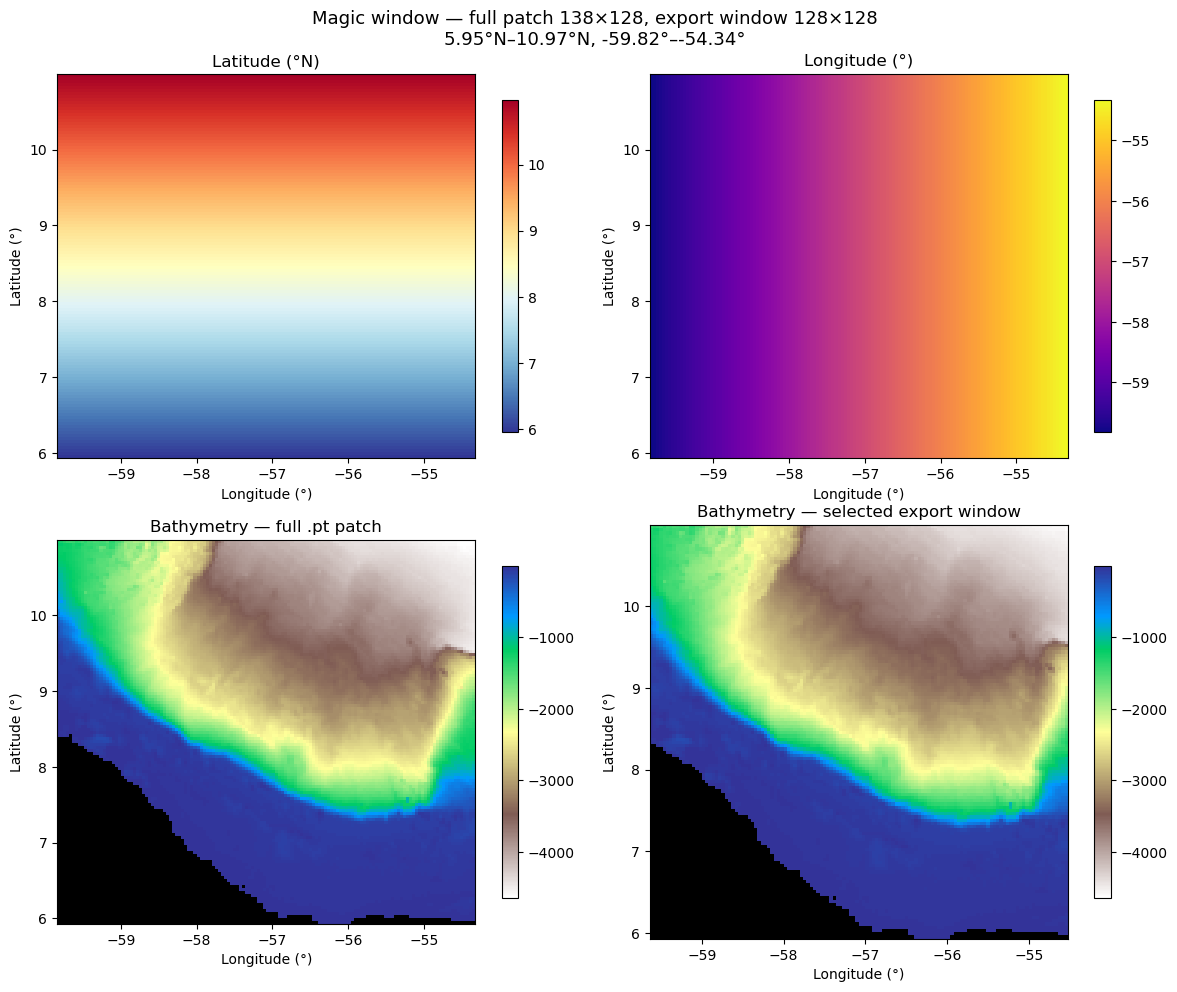

In [6]:
valid_bathy = np.isfinite(bathy) & (bathy != 0)
bathy_stats = {
    "valid ocean cells": f"{valid_bathy.sum()} / {bathy.size} ({100 * valid_bathy.mean():.1f}%)",
    "land/invalid (NaN or 0)": f"{(~valid_bathy).sum()}",
    "min depth (m)": f"{np.nanmin(bathy[valid_bathy]):.1f}" if valid_bathy.any() else "n/a",
    "max depth (m)": f"{np.nanmax(bathy[valid_bathy]):.1f}" if valid_bathy.any() else "n/a",
    "mean depth (m)": f"{np.nanmean(bathy[valid_bathy]):.1f}" if valid_bathy.any() else "n/a",
}
display(pd.DataFrame(list(bathy_stats.items()), columns=["stat", "value"]))

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
bathy_cmap = bathymetry_cmap()

panels = [
    (axes[0, 0], lat, "Latitude (°N)", "RdYlBu_r"),
    (axes[0, 1], lon, "Longitude (°)", "plasma"),
]
for ax, field, title, cmap in panels:
    mesh = ax.pcolormesh(lon_1d, lat_1d, field.T, shading="auto", cmap=cmap)
    ax.set_title(title)
    ax.set_xlabel("Longitude (°)")
    ax.set_ylabel("Latitude (°)")
    ax.set_aspect("equal")
    fig.colorbar(mesh, ax=ax, shrink=0.8)

# Full patch bathymetry (black land)
ax = axes[1, 0]
masked_patch = mask_bathymetry_land(bathy_full_patch)
mesh = ax.pcolormesh(
    lon_1d,
    lat_1d,
    masked_patch.T,
    shading="auto",
    cmap=bathy_cmap,
    vmin=_bathy_vmin,
    vmax=_bathy_vmax,
)
ax.set_title("Bathymetry — full .pt patch")
ax.set_xlabel("Longitude (°)")
ax.set_ylabel("Latitude (°)")
ax.set_aspect("equal")
fig.colorbar(mesh, ax=ax, shrink=0.8)

# Selected window + corners
ax = axes[1, 1]
masked_sel = mask_bathymetry_land(bathy_selected)
mesh = ax.pcolormesh(
    lon_1d_selected,
    lat_1d_selected,
    masked_sel.T,
    shading="auto",
    cmap=bathy_cmap,
    vmin=_bathy_vmin,
    vmax=_bathy_vmax,
)
for label, (la, lo) in corners.items():
    if patch_col_start <= int(np.argmin(np.abs(lon[:, 0] - lo))) < patch_col_end:
        ax.plot(lo, la, "ko", ms=5)
        short = label.split(")")[0] + ")"
        ax.annotate(short, (lo, la), textcoords="offset points", xytext=(4, 4), fontsize=8)
ax.set_title("Bathymetry — selected export window")
ax.set_xlabel("Longitude (°)")
ax.set_ylabel("Latitude (°)")
ax.set_aspect("equal")
fig.colorbar(mesh, ax=ax, shrink=0.8)

fig.suptitle(
    f"Magic window — full patch {width}×{height}, export window {bathy_selected.shape[0]}×{bathy_selected.shape[1]}\n"
    f"{lat_min:.2f}°N–{lat_max:.2f}°N, {lon_min:.2f}°–{lon_max:.2f}°",
    fontsize=13,
)
plt.tight_layout()
plt.show()


## Bathymetry distribution

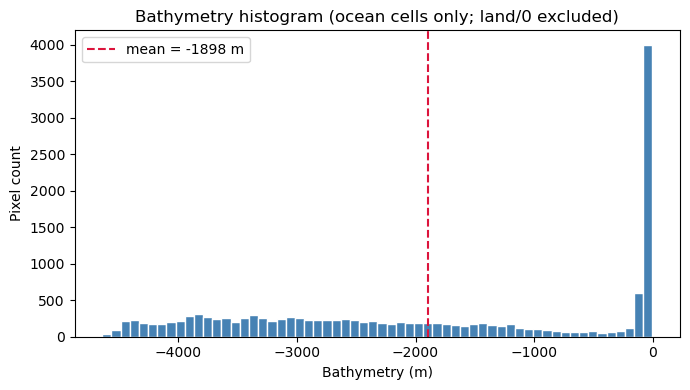

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(bathy[valid_bathy].ravel(), bins=60, color="steelblue", edgecolor="white")
ax.set_xlabel("Bathymetry (m)")
ax.set_ylabel("Pixel count")
ax.set_title("Bathymetry histogram (ocean cells only; land/0 excluded)")
ax.axvline(np.nanmean(bathy[valid_bathy]), color="crimson", ls="--", label=f"mean = {np.nanmean(bathy[valid_bathy]):.0f} m")
ax.legend()
plt.tight_layout()
plt.show()


In [8]:
# Bathymetry == 0 as fraction of the whole selected export window
_sel = np.asarray(bathy_selected)
_n_sel = _sel.size
_n_zero_sel = int(np.sum(_sel == 0))
_n_nan_sel = int(np.sum(~np.isfinite(_sel)))
_n_land_sel = int(np.sum((~np.isfinite(_sel)) | (_sel == 0)))
_pct_zero_sel = 100.0 * _n_zero_sel / _n_sel

print(f"Selected export window: {_sel.shape[0]}×{_sel.shape[1]} = {_n_sel:,} pixels")
print(f"Bathymetry == 0: {_n_zero_sel:,} / {_n_sel:,}  →  {_pct_zero_sel:.2f}% of selected window")
print(f"NaN (land):       {_n_nan_sel:,} / {_n_sel:,}  →  {100.0 * _n_nan_sel / _n_sel:.2f}%")
print(f"Land/invalid (NaN or 0): {_n_land_sel:,} / {_n_sel:,}  →  {100.0 * _n_land_sel / _n_sel:.2f}%")

display(
    pd.DataFrame(
        {
            "count": [_n_zero_sel, _n_nan_sel, _n_land_sel, _n_sel - _n_land_sel],
            "% of selected window": [
                _pct_zero_sel,
                100.0 * _n_nan_sel / _n_sel,
                100.0 * _n_land_sel / _n_sel,
                100.0 * (_n_sel - _n_land_sel) / _n_sel,
            ],
        },
        index=[
            "bathymetry == 0",
            "NaN",
            "land/invalid (NaN or 0)",
            "valid ocean (finite, ≠ 0)",
        ],
    ).round({"% of selected window": 2})
)

Selected export window: 128×128 = 16,384 pixels
Bathymetry == 0: 0 / 16,384  →  0.00% of selected window
NaN (land):       2,272 / 16,384  →  13.87%
Land/invalid (NaN or 0): 2,272 / 16,384  →  13.87%


,count,% of selected window
bathymetry == 0,0,0.00
NaN,2272,13.87
land/invalid (NaN or 0),2272,13.87
"valid ocean (finite, ≠ 0)",14112,86.13


## Slice selection on parent grid

`magic_window` stores normalized fractions on the full zarr. Multiplying by the parent grid size recovers `row_slice` and `col_slice`.

,item,value
0,magic_window lat fraction,"(0.524362, 0.821346)"
1,magic_window lon fraction,"(0.146535, 0.4)"
2,stored row_slice,"(226, 354)"
3,stored col_slice,"(80, 218)"
4,derived row_slice,"(226, 354)"
5,derived col_slice,"(80, 218)"
6,row match,True
7,col match,True


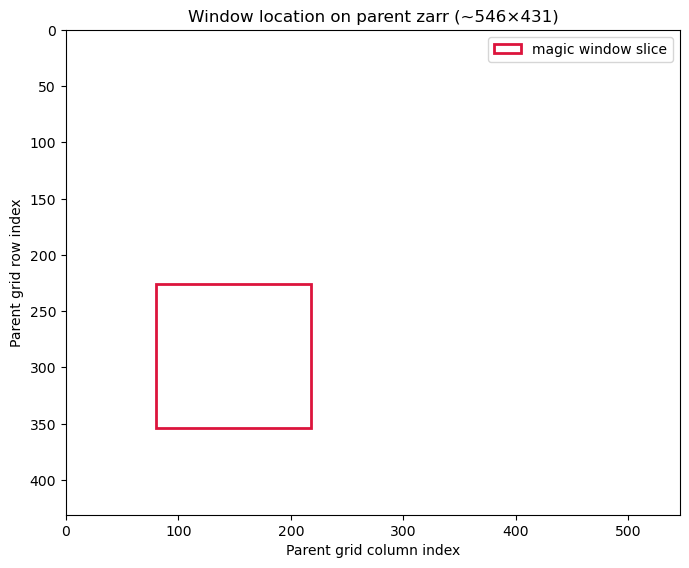

In [9]:
lat_frac, lon_frac = magic_window
derived_row = (
    int(round(lat_frac[0] * parent_h)),
    int(round(lat_frac[1] * parent_h)),
)
derived_col = (
    int(round(lon_frac[0] * parent_w)),
    int(round(lon_frac[1] * parent_w)),
)

slice_rows = [
    ("magic_window lat fraction", str(lat_frac)),
    ("magic_window lon fraction", str(lon_frac)),
    ("stored row_slice", str(row_slice)),
    ("stored col_slice", str(col_slice)),
    ("derived row_slice", str(derived_row)),
    ("derived col_slice", str(derived_col)),
    ("row match", derived_row == tuple(row_slice)),
    ("col match", derived_col == tuple(col_slice)),
]
display(pd.DataFrame(slice_rows, columns=["item", "value"]))

fig, ax = plt.subplots(figsize=(7, 6))
ax.set_xlim(0, parent_w)
ax.set_ylim(parent_h, 0)
ax.add_patch(
    Rectangle(
        (col_slice[0], row_slice[0]),
        n_cols,
        n_rows,
        fill=False,
        edgecolor="crimson",
        linewidth=2,
        label="magic window slice",
    )
)
ax.set_xlabel("Parent grid column index")
ax.set_ylabel("Parent grid row index")
ax.set_title(f"Window location on parent zarr (~{parent_w:.0f}×{parent_h:.0f})")
ax.legend(loc="upper right")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## Export window selection

Window comparison and coordinate lookup moved to **`Magic_window_window_selection.ipynb`** (magic, small/large @ magic pivot, legacy small/large fix windows).
